# Statrtup Failure Prediction Notebook

## 1. Data Preparation

In [779]:
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import accuracy_score, roc_auc_score, mutual_info_score, root_mean_squared_error
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

In [780]:
data = 'data/Startup Failures.csv'

In [781]:
df = pd.read_csv(data)

### Formating column names

In [782]:
df.columns =  df.columns.str.lower().str.replace(' ','_')
df.head()

,name,sector,years_of_operation,what_they_did,how_much_they_raised,why_they_failed,takeaway,giants,no_budget,competition,poor_market_fit,acquisition_stagnation,platform_dependency,monetization_failure,niche_limits,execution_flaws,trend_shifts,toxicity/trust_issues,regulatory_pressure,overhype
0,Avant,Finance and Insurance,2012-2023,Online personal loans,$655M,Lost to LendingClub and high defaults,Lending needs risk balance,1,1,1,0,0,0,0,0,0,0,0.0,0.0,0.0
1,Bitpass,Finance and Insurance,2002-2008,Micropayments platform,$2M,Lost to PayPal and low adoption,Micropayments need mass use,1,0,1,1,0,0,0,0,0,0,0.0,0.0,0.0
2,Cake Financial,Finance and Insurance,2006-2011,Portfolio tracking tool,$3M,Lost to Mint and sold to TradeKing,Finance tools need scale,1,0,1,0,1,0,0,0,0,0,0.0,0.0,0.0
3,Circle,Finance and Insurance,2013-2023,Crypto payments and stablecoin,$500M,Lost to Coinbase and market shifts,Crypto needs stability,1,0,1,0,0,0,0,0,0,1,0.0,0.0,0.0
4,Clarity Money,Finance and Insurance,2016-2022,Personal finance app,$11M,Lost to Mint/Acorns and sold to Goldman,Finance apps need edge,1,0,1,0,1,0,0,0,0,0,0.0,0.0,0.0


###  Converting 'how_much_they_raised_column' into numerical values

In [783]:
def clean_how_much_they_raised(text):
    number = pd.to_numeric(re.sub(r'[^\d.]','', str(text)), errors='coerce')
    
    if 'B' in str(text):
        return number * 1_000_000_000
    
    if 'M' in str(text):
        return number * 1_000_000

    if 'K' in str(text):
        return number * 1_000

    return 0

df['total_funding'] = df.how_much_they_raised.apply(clean_how_much_they_raised)

### Cleaning and converting 'years_of_operation' column to numbers

In [784]:
def clean_years_of_operation(text):
    years = re.findall(r'\d{4}', str(text))

    return int(years[1]) - int(years[0])

df.years_of_operation = df.years_of_operation.apply(clean_years_of_operation)

In [785]:
df.head()

,name,sector,years_of_operation,what_they_did,how_much_they_raised,why_they_failed,takeaway,giants,no_budget,competition,...,acquisition_stagnation,platform_dependency,monetization_failure,niche_limits,execution_flaws,trend_shifts,toxicity/trust_issues,regulatory_pressure,overhype,total_funding
0,Avant,Finance and Insurance,11,Online personal loans,$655M,Lost to LendingClub and high defaults,Lending needs risk balance,1,1,1,...,0,0,0,0,0,0,0.0,0.0,0.0,655000000.0
1,Bitpass,Finance and Insurance,6,Micropayments platform,$2M,Lost to PayPal and low adoption,Micropayments need mass use,1,0,1,...,0,0,0,0,0,0,0.0,0.0,0.0,2000000.0
2,Cake Financial,Finance and Insurance,5,Portfolio tracking tool,$3M,Lost to Mint and sold to TradeKing,Finance tools need scale,1,0,1,...,1,0,0,0,0,0,0.0,0.0,0.0,3000000.0
3,Circle,Finance and Insurance,10,Crypto payments and stablecoin,$500M,Lost to Coinbase and market shifts,Crypto needs stability,1,0,1,...,0,0,0,0,0,1,0.0,0.0,0.0,500000000.0
4,Clarity Money,Finance and Insurance,6,Personal finance app,$11M,Lost to Mint/Acorns and sold to Goldman,Finance apps need edge,1,0,1,...,1,0,0,0,0,0,0.0,0.0,0.0,11000000.0


### Handling missing values

In [786]:
df.isna().sum()

name                       0
sector                     0
years_of_operation         0
what_they_did              0
how_much_they_raised       0
why_they_failed            0
takeaway                   0
giants                     0
no_budget                  0
competition                0
poor_market_fit            0
acquisition_stagnation     0
platform_dependency        0
monetization_failure       0
niche_limits               0
execution_flaws            0
trend_shifts               0
toxicity/trust_issues     26
regulatory_pressure       26
overhype                  27
total_funding              1
dtype: int64

In [787]:
df = df.fillna(0)

## 2. EDA (Explanatory Data Analysis)

In [788]:
df['sector'].value_counts()

sector
Information                        156
Retail Trade                        90
Finance and Insurance               47
Manufacturing                       30
Accommodation and Food Services     26
Name: count, dtype: int64

Text(0.5, 1.0, 'Startup Distribution by Sector')

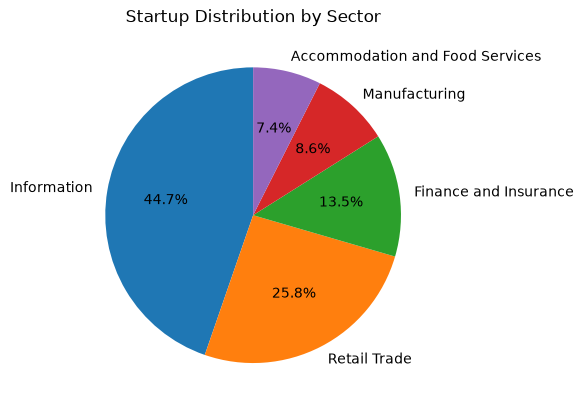

In [789]:
df.sector.value_counts().plot.pie(
    autopct="%1.1f%%", startangle=90
)
plt.title('Startup Distribution by Sector')

[Text(-30, 0, '174'),
 Text(-30, 0, '357'),
 Text(-30, 0, '1292'),
 Text(-30, 0, '209'),
 Text(-30, 0, '631')]

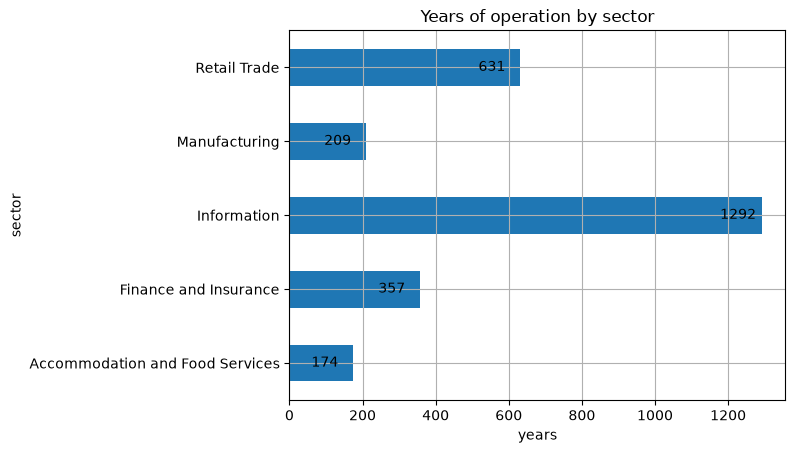

In [790]:
ax = df.groupby('sector')['years_of_operation'].agg('sum').plot.barh()
plt.title('Years of operation by sector')
plt.xlabel('years')
plt.grid()
plt.bar_label(ax.containers[0], padding=-30)

Text(0.5, 1.0, 'Sum of Funding by Sector')

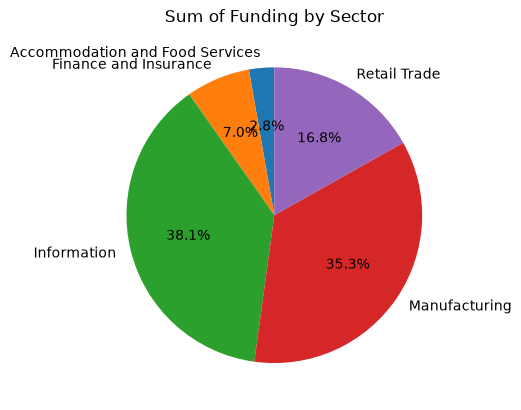

In [791]:
df.groupby('sector')['total_funding'].agg('sum').plot.pie(
    autopct="%1.1f%%", startangle=90
)
plt.title('Sum of Funding by Sector')

In [792]:
df.total_funding = np.log1p(df.total_funding )

[Text(-30, 0, '20'),
 Text(-30, 0, '47'),
 Text(-30, 0, '115'),
 Text(-30, 0, '30'),
 Text(-30, 0, '44')]

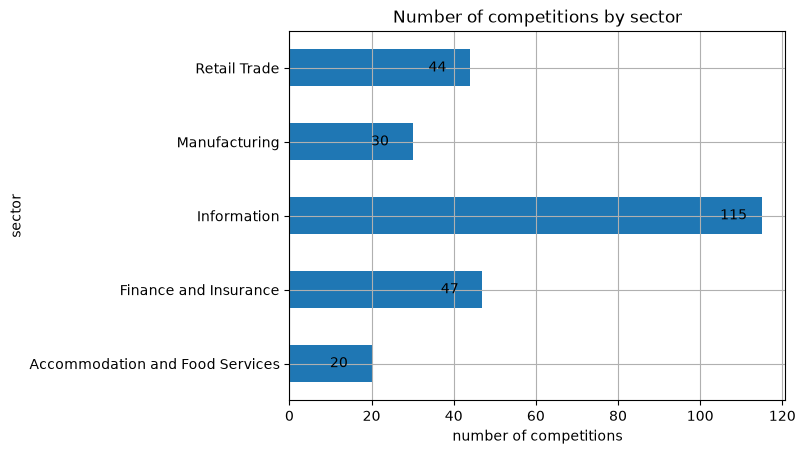

In [793]:
ax = df.groupby('sector')['competition'].agg('sum').plot.barh()
plt.title('Number of competitions by sector')
plt.xlabel('number of competitions')
plt.grid()
plt.bar_label(ax.containers[0], padding=-30)

### Feature importance analysis

In [794]:
df.columns

Index(['name', 'sector', 'years_of_operation', 'what_they_did',
       'how_much_they_raised', 'why_they_failed', 'takeaway', 'giants',
       'no_budget', 'competition', 'poor_market_fit', 'acquisition_stagnation',
       'platform_dependency', 'monetization_failure', 'niche_limits',
       'execution_flaws', 'trend_shifts', 'toxicity/trust_issues',
       'regulatory_pressure', 'overhype', 'total_funding'],
      dtype='str')

In [795]:
categorical = ['sector','giants',
       'no_budget', 'competition', 'acquisition_stagnation',
       'platform_dependency', 'monetization_failure', 'niche_limits',
       'execution_flaws', 'trend_shifts', 'toxicity/trust_issues',
       'regulatory_pressure', 'overhype']

numerical = ['years_of_operation', 'total_funding']

##### - Categorical Features Analysis

In [796]:
mutual_info_scores = []
for c in categorical:
    mutual_info_scores.append(round(mutual_info_score(df.poor_market_fit, df[c]), 5) * 100)

mutual_info_scores_df = pd.DataFrame(mutual_info_scores, index=categorical, columns=['mutual_info_score'])

[Text(2, 0, '0.006'),
 Text(2, 0, '0.018'),
 Text(2, 0, '0.035'),
 Text(2, 0, '0.075'),
 Text(2, 0, '0.874'),
 Text(2, 0, '1.086'),
 Text(2, 0, '1.459'),
 Text(2, 0, '1.549'),
 Text(2, 0, '1.723'),
 Text(2, 0, '1.962'),
 Text(2, 0, '2.233'),
 Text(2, 0, '2.535'),
 Text(2, 0, '3.051')]

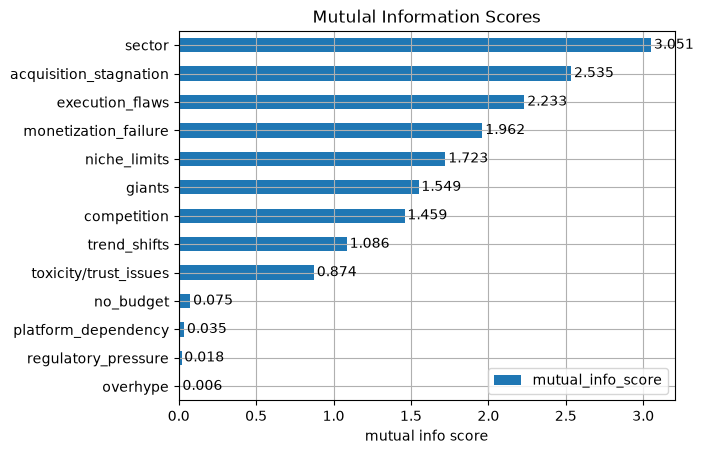

In [797]:
ax = mutual_info_scores_df.sort_values(by='mutual_info_score').plot.barh()
plt.grid()
plt.title('Mutulal Information Scores')
plt.xlabel('mutual info score')
plt.bar_label(ax.containers[0], padding=2)

##### - Numerical Features Analysis

In [798]:
df[numerical].corrwith(df.poor_market_fit)

years_of_operation   -0.301885
total_funding        -0.224738
dtype: float64

- The Features with highest degree of importance are `sector` ,`competition`, `giants` ,`niche_limits` ,`monetization_failure`, `execution_flaws`, `acquisition_stagnation`, `years_of_operation`, `total_funding`


## 3. Model Selection & Hypyerparameter Tuning

### Data Splitting 

In [799]:
features = ['sector','competition', 'giants' ,'niche_limits' ,'monetization_failure', 'execution_flaws', 'acquisition_stagnation', 'years_of_operation']
y = df.poor_market_fit

In [800]:
df_train_full, df_test, y_train_full, y_test = train_test_split(df[features], y, test_size=0.2, random_state=1)
df_train, df_val, y_train, y_val = train_test_split(df_train_full, y_train_full, test_size=0.25 ,random_state=1)

In [801]:
vectorizer = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')


X_train = vectorizer.fit_transform(train_dicts)
X_val = vectorizer.transform(val_dicts)

In [802]:
models = {
    'lr': {
             'model': LogisticRegression, 
             'parameters': {
                 'C': [0.1, 1, 10, 100],  
                 'max_iter': [200, 300, 400, 500]
             },
         },
    'dt':  {
             'model': DecisionTreeClassifier,
             'parameters': {
                 'max_depth': [None, 5, 10, 20],
                 'min_samples_split': [2, 5, 10, 25],
             },
         },
        'rf':{
             'model': RandomForestClassifier,
             'parameters': {
                 'n_estimators': [10, 50, 100, 200],  
                 'max_depth': [None, 5, 10, 20],
             },
         },
}
     

In [803]:
scores = []

In [804]:
model = models['lr']['model']
parameters = models['lr']['parameters']


for c in parameters['C'] :
    for max_iter in parameters['max_iter']:
        m = model(C=c, max_iter=max_iter)

        m.fit(X_train, y_train)
        y_pred = m.predict_proba(X_val)[:,1]
        score = roc_auc_score(y_val, y_pred)
        scores.append({'model':'lr', 'C':c, 'max_iter':max_iter, 'score':score})


In [805]:
model = models['dt']['model']
parameters = models['dt']['parameters']


for max_depth in parameters['max_depth'] :
    for min_samples_split in parameters['min_samples_split']:
        m = model(max_depth=max_depth, min_samples_split=min_samples_split)

        m.fit(X_train, y_train)
        y_pred = m.predict_proba(X_val)[:,1]
        score = roc_auc_score(y_val, y_pred)
        scores.append({'model':'dt', 'max_depth':max_depth, 'min_samples_split':min_samples_split, 'score':score})


In [806]:
model = models['rf']['model']
parameters = models['rf']['parameters']


for max_depth in parameters['max_depth'] :
    for n_estimators in parameters['n_estimators']:
        m = model(max_depth=max_depth, n_estimators=n_estimators)

        m.fit(X_train, y_train)
        y_pred = m.predict_proba(X_val)[:,1]
        score = roc_auc_score(y_val, y_pred)
        scores.append({'model':'rf', 'max_depth':max_depth, 'n_estimators':n_estimators, 'score':score})


In [807]:
print(max(scores, key=lambda x : x['score']))

{'model': 'lr', 'C': 100, 'max_iter': 200, 'score': 0.9190051020408163}


- The best model is `LogisticRegression` with `C` of `100` and `max_iter` of `200`.

In [808]:
test_dicts = df_test.to_dict(orient='records')
X_test = vectorizer.transform(test_dicts)

class_model = LogisticRegression(C=100, max_iter=200)
class_model.fit(X_train, y_train)

y_pred = class_model.predict_proba(X_test)[:,1]

roc_auc_score(y_test, y_pred)

0.8446712018140589

## Regression Task

Prediction how much fund will a startup raise

In [809]:
features = ['sector','competition', 'giants' ,'niche_limits' ,'monetization_failure', 'execution_flaws', 'acquisition_stagnation', 'years_of_operation']
y = df.total_funding

In [810]:
df_train_full, df_test, y_train_full, y_test = train_test_split(df[features], y, test_size=0.2, random_state=1)
df_train, df_val, y_train, y_val = train_test_split(df_train_full, y_train_full, test_size=0.25 ,random_state=1)

In [811]:
vectorizer = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')


X_train = vectorizer.fit_transform(train_dicts)
X_val = vectorizer.transform(val_dicts)

In [812]:
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

y_pred = reg_model.predict(X_val)

root_mean_squared_error(y_val, y_pred)

3.1525705059128177

In [813]:
test_dicts = df_test.to_dict(orient='records')
X_test = vectorizer.transform(test_dicts)

y_pred = reg_model.predict(X_test)

root_mean_squared_error(y_test, y_pred)

2.70520825276225